# Enterprise Multi-Modal Data Visualization & Storytelling
## Global Superstore 2011-2014 — *"Growing sales, leaking profit"*

**Dataset:** Global Superstore (51,290 order lines, 24 fields, 147 countries, 7 markets, 2011-2014).
It covers every field type the brief asks for:

| Data type | Fields |
|---|---|
| Continuous | `Sales`, `Profit`, `Discount`, `Shipping Cost`, `Quantity` |
| Categorical | `Segment`, `Category`, `Sub-Category`, `Ship Mode`, `Order Priority`, `Market` |
| Temporal | `Order Date`, `Ship Date` |
| Geospatial | `Country`, `State`, `City`, `Region`, `Market` (+ ISO-3 codes we add) |

**Notebook map (visual taxonomy):**
0. Setup, palettes & decluttered style
1. Data wrangling (cleaning, typing, imputation, feature engineering, star schema export)
2. Amounts — bar charts with strict 0-baseline
3. Distributions — histograms, KDE, box & violin plots (log scale where ranges are exponential)
4. Uncertainty — 95 % confidence-interval bands and error bars
5. X-Y relationships — Seaborn correlation heatmap + Plotly interactive bubble chart
6. Geospatial — choropleth (geographic coordinate system)
7. Proportions — treemap and stacked area
8. Cyclical data — polar (radial) coordinate system
9. Key numbers for the executive story

All figures are exported to `outputs/static/` (PNG @ 200 dpi + SVG vector) and `outputs/html/` (interactive Plotly).

## 0. Setup — libraries, colour system and chart style

In [1]:
# --- Core libraries -------------------------------------------------------
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Output folders --------------------------------------------------------
STATIC = Path("outputs/static"); STATIC.mkdir(parents=True, exist_ok=True)
HTML = Path("outputs/html");     HTML.mkdir(parents=True, exist_ok=True)
PROCESSED = Path("data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)

# --- Colour system (colour-blind safe) ------------------------------------
# Qualitative palette for discrete categories (markets). Order is FIXED so the
# same market always gets the same colour in every chart (colour follows the
# entity, never its rank). Validated for CVD separation (worst adjacent
# protan/deutan ΔE 9.1 ≥ 8 target).
MARKET_ORDER = ["APAC", "EU", "US", "LATAM", "EMEA", "Africa", "Canada"]
QUAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
MARKET_COLORS = dict(zip(MARKET_ORDER, QUAL))
CATEGORY_COLORS = {"Technology": QUAL[0], "Furniture": QUAL[1], "Office Supplies": QUAL[2]}

SEQUENTIAL = "viridis"          # ordered magnitudes (one perceptual ramp, CVD safe)
DIVERGING = "RdBu"              # profit/loss variance around a neutral 0 midpoint
NEG, NEUTRAL, POS = "#c0392b", "#bdbdbd", "#2166ac"   # loss / neutral / profit
HIGHLIGHT, MUTED = "#c0392b", "#c9c9c9"               # pre-attentive emphasis

# --- Decluttered default style --------------------------------------------
# No top/right spines, light horizontal grid only, no chart junk.
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.grid": False, "font.size": 10,
})

def save(fig, name):
    """Export a Matplotlib figure as high-res PNG and vector SVG."""
    fig.savefig(STATIC / f"{name}.png")
    fig.savefig(STATIC / f"{name}.svg")
    print(f"saved -> outputs/static/{name}.png / .svg")

def save_plotly(fig, name, width=1100, height=600):
    """Export a Plotly figure as interactive HTML + static PNG/SVG."""
    fig.write_html(HTML / f"{name}.html", include_plotlyjs="cdn")
    fig.write_image(STATIC / f"{name}.png", width=width, height=height, scale=2)
    fig.write_image(STATIC / f"{name}.svg", width=width, height=height)
    print(f"saved -> outputs/html/{name}.html (+ static png/svg)")

usd = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:.0f}K")

## 1. Data wrangling (Role 1 — Data Architect & Wrangler)
### 1.1 Acquisition & first profile
The raw CSV is Latin-1 encoded (accented city names), so we read it with `encoding="latin-1"`.

In [2]:
raw = pd.read_csv("data/raw/Global_Superstore2.csv", encoding="latin-1")
print("Shape:", raw.shape)
print("Duplicated rows:", raw.duplicated().sum())
print("\nMissing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
raw.head(3)

Shape: (51290, 24)
Duplicated rows: 0

Missing values per column:


Postal Code    41296
dtype: int64


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium


### 1.2 Cleaning, typing & missing-value imputation
* **Dates** come as `dd-mm-yyyy` strings → parse with `dayfirst=True`.
* **Postal Code** is missing for 80.5 % of rows. It only exists for US addresses (the US postal system), so the
  gaps are *structurally missing*, not random. Imputing a fake number would be wrong; we impute the
  explicit category `"Not applicable"` for non-US rows and keep codes as text (leading zeros).
* Text fields are stripped of stray whitespace; categorical fields get the `category` dtype (memory + ordering).
* Outliers are **flagged, not deleted** (IQR rule): large B2B orders are real business events.

In [3]:
df = raw.copy()

# Standardise column names to snake_case for easier coding
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("-", "_").str.replace(" ", "_"))

# Temporal fields
df["order_date"] = pd.to_datetime(df["order_date"], dayfirst=True)
df["ship_date"] = pd.to_datetime(df["ship_date"], dayfirst=True)

# Text hygiene
obj_cols = df.select_dtypes("object").columns
df[obj_cols] = df[obj_cols].apply(lambda s: s.str.strip())

# Structural missingness -> explicit category (only US uses postal codes)
print("Missing postal codes by market:\n", df.loc[df["postal_code"].isna(), "market"].value_counts())
df["postal_code"] = (df["postal_code"].astype("Int64").astype("string")
                     .fillna("Not applicable"))

# Ordered categorical types
df["order_priority"] = pd.Categorical(df["order_priority"],
                                      ["Low", "Medium", "High", "Critical"], ordered=True)
df["ship_mode"] = pd.Categorical(df["ship_mode"],
                                 ["Same Day", "First Class", "Second Class", "Standard Class"], ordered=True)
for c in ["segment", "category", "sub_category", "market", "region"]:
    df[c] = df[c].astype("category")

# Sanity rules: no negative sales/qty, discount in [0,1], ship after order
assert (df["sales"] > 0).all() and (df["quantity"] > 0).all()
assert df["discount"].between(0, 1).all()
assert (df["ship_date"] >= df["order_date"]).all()
print("\nAll integrity checks passed. Remaining NaNs:", int(df.isna().sum().sum()))

Missing postal codes by market:
 market
APAC      11002
LATAM     10294
EU        10000
EMEA       5029
Africa     4587
Canada      384
Name: count, dtype: int64

All integrity checks passed. Remaining NaNs: 0


### 1.3 Feature engineering

In [4]:
# Time hierarchy (Year > Quarter > Month) used for drill-down in the dashboard
df["order_year"] = df["order_date"].dt.year
df["order_quarter"] = df["order_date"].dt.quarter
df["order_month"] = df["order_date"].dt.month
df["order_month_name"] = df["order_date"].dt.strftime("%b")
df["year_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

# Business KPIs
df["ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["profit_margin"] = df["profit"] / df["sales"]          # ratio, can be negative
df["is_loss"] = df["profit"] < 0
df["unit_price"] = df["sales"] / df["quantity"]

# Discount bands (ordinal) — the key driver we will investigate
bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"]
df["discount_band"] = pd.cut(df["discount"], bins=bins, labels=labels, ordered=True)

# Geospatial enrichment: ISO-3 country codes for reliable choropleth matching
iso = pd.read_csv("data/country_iso3.csv")
df = df.merge(iso, left_on="country", right_on="Country", how="left").drop(columns="Country")
df = df.rename(columns={"ISO3": "iso3"})
assert df["iso3"].notna().all(), "every country must map to an ISO-3 code"

# IQR outlier flag on sales (kept, only flagged)
q1, q3 = df["sales"].quantile([.25, .75])
df["sales_outlier"] = df["sales"] > q3 + 1.5 * (q3 - q1)
print(f"Sales outliers flagged: {df['sales_outlier'].mean():.1%} of rows (kept)")
df[["order_date", "market", "country", "iso3", "sub_category", "sales",
    "discount", "discount_band", "profit", "profit_margin", "ship_days"]].head()

Sales outliers flagged: 11.0% of rows (kept)


,order_date,market,country,iso3,sub_category,sales,discount,discount_band,profit,profit_margin,ship_days
0,2012-07-31,US,United States,USA,Accessories,2309.650,0.0,0%,762.1845,0.330000,0
1,2013-02-05,APAC,Australia,AUS,Chairs,3709.395,0.1,1-10%,-288.7650,-0.077847,2
2,2013-10-17,APAC,Australia,AUS,Phones,5175.171,0.1,1-10%,919.9710,0.177766,1
3,2013-01-28,EU,Germany,DEU,Phones,2892.510,0.1,1-10%,-96.5400,-0.033376,2
4,2013-11-05,Africa,Senegal,SEN,Copiers,2832.960,0.0,0%,311.5200,0.109963,1


### 1.4 Star schema export (for the BI dashboard)
One fact table (order lines) and four dimensions. Any BI tool (Tableau, Power BI, or our open-source Dash
dashboard) can join them on the surrogate keys. We also export one flat, denormalised file for convenience.

In [5]:
# Dimensions -----------------------------------------------------------------
dim_customer = (df[["customer_id", "customer_name", "segment"]]
                .drop_duplicates("customer_id").reset_index(drop=True))
dim_product = (df[["product_id", "product_name", "category", "sub_category"]]
               .drop_duplicates("product_id").reset_index(drop=True))
dim_geo = (df[["city", "state", "country", "iso3", "region", "market"]]
           .drop_duplicates().reset_index(drop=True))
dim_geo.insert(0, "geo_key", range(1, len(dim_geo) + 1))
dim_date = pd.DataFrame({"date": pd.date_range(df["order_date"].min(), df["ship_date"].max())})
dim_date["date_key"] = dim_date["date"].dt.strftime("%Y%m%d").astype(int)
dim_date["year"] = dim_date["date"].dt.year
dim_date["quarter"] = dim_date["date"].dt.quarter
dim_date["month"] = dim_date["date"].dt.month
dim_date["month_name"] = dim_date["date"].dt.strftime("%b")
dim_date["weekday"] = dim_date["date"].dt.day_name()

# Fact table -------------------------------------------------------------------
fact = df.merge(dim_geo, on=["city", "state", "country", "iso3", "region", "market"])
fact["order_date_key"] = fact["order_date"].dt.strftime("%Y%m%d").astype(int)
fact["ship_date_key"] = fact["ship_date"].dt.strftime("%Y%m%d").astype(int)
fact_orders = fact[["row_id", "order_id", "order_date_key", "ship_date_key", "customer_id",
                    "product_id", "geo_key", "ship_mode", "order_priority", "sales", "quantity",
                    "discount", "discount_band", "profit", "profit_margin", "shipping_cost", "ship_days"]]

for name, t in {"fact_orders": fact_orders, "dim_customer": dim_customer, "dim_product": dim_product,
                "dim_geography": dim_geo, "dim_date": dim_date}.items():
    t.to_csv(PROCESSED / f"{name}.csv", index=False)
    print(f"{name:14s} {t.shape}")

df.to_csv(PROCESSED / "superstore_clean.csv", index=False)
print("flat file     ", df.shape)

fact_orders    (51290, 17)
dim_customer   (1590, 3)
dim_product    (10292, 4)
dim_geography  (3819, 7)
dim_date       (1468, 7)


flat file      (51290, 36)


## 2. Amounts — where do sales and profit come from?
**Encoding:** horizontal bars (long labels), sorted, **strict 0-baseline**. Profit uses a *diverging* encoding:
blue = profit, red = loss, so the only loss-making sub-category pops out pre-attentively.

saved -> outputs/static/01_amounts_subcategory.png / .svg


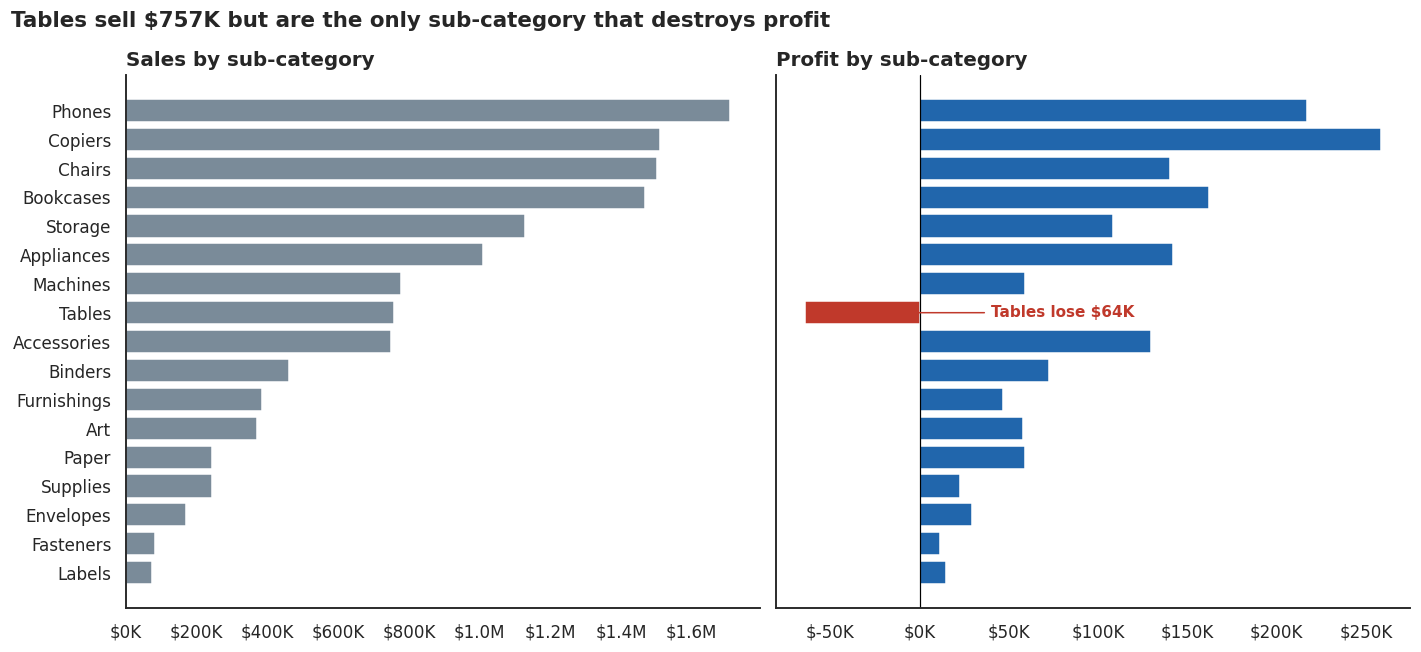

In [6]:
sub = (df.groupby("sub_category", observed=True)[["sales", "profit"]].sum()
         .sort_values("sales"))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)

# Left: sales (amount, single neutral colour — no need for colour to encode anything)
axes[0].barh(sub.index, sub["sales"], color="#7a8b99")
axes[0].set_title("Sales by sub-category")
axes[0].xaxis.set_major_formatter(usd)
axes[0].set_xlim(left=0)                                   # strict 0-baseline

# Right: profit, diverging colour around 0
colors = [NEG if v < 0 else POS for v in sub["profit"]]
axes[1].barh(sub.index, sub["profit"], color=colors)
axes[1].axvline(0, color="black", lw=0.8)                  # explicit zero line
axes[1].set_title("Profit by sub-category")
axes[1].xaxis.set_major_formatter(usd)
t = sub.loc["Tables", "profit"]
axes[1].annotate(f"Tables lose ${-t/1e3:.0f}K", xy=(t, "Tables"), xytext=(40_000, "Tables"),
                 va="center", color=NEG, fontweight="bold",
                 arrowprops=dict(arrowstyle="->", color=NEG))
for ax in axes:
    ax.tick_params(left=False)
fig.suptitle("Tables sell $757K but are the only sub-category that destroys profit",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "01_amounts_subcategory")
plt.show()

saved -> outputs/static/02_amounts_yearly.png / .svg


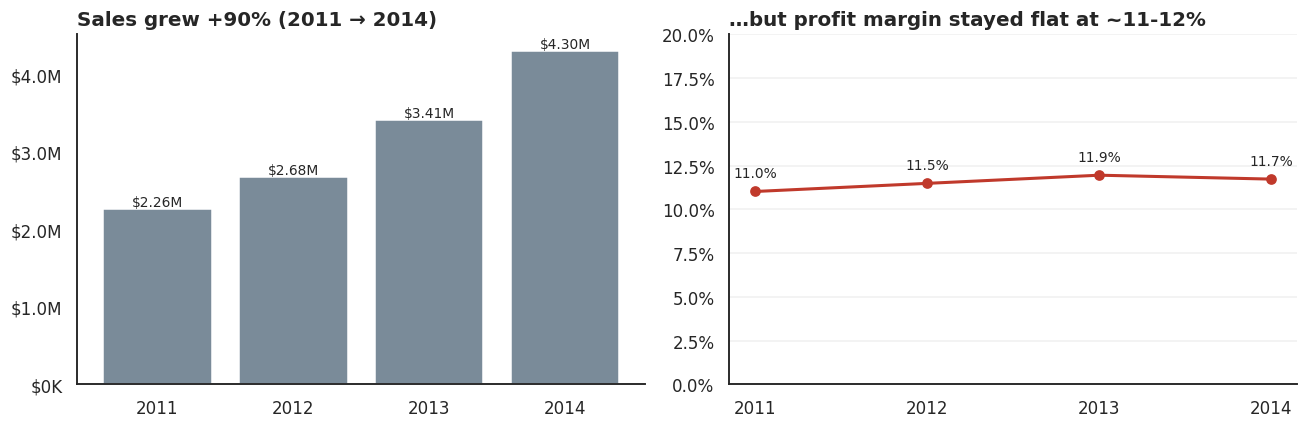

,sales,profit,margin
order_year,,,
2011,2.259451e+06,248940.81154,0.110178
2012,2.677439e+06,307415.27910,0.114817
2013,3.405746e+06,406935.23018,0.119485
2014,4.299866e+06,504165.97046,0.117252


In [7]:
# Yearly sales vs profit margin — two different scales, so TWO aligned charts
# (never a dual-axis chart).
yr = df.groupby("order_year")[["sales", "profit"]].sum()
yr["margin"] = yr["profit"] / yr["sales"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(yr.index.astype(str), yr["sales"], color="#7a8b99")
a1.set_ylim(bottom=0); a1.yaxis.set_major_formatter(usd)
a1.set_title("Sales grew +90% (2011 → 2014)")
for x, v in zip(yr.index.astype(str), yr["sales"]):
    a1.text(x, v, f"${v/1e6:.2f}M", ha="center", va="bottom", fontsize=9)

a2.plot(yr.index.astype(str), yr["margin"], marker="o", lw=2, color=HIGHLIGHT)
a2.set_ylim(0, 0.2); a2.yaxis.set_major_formatter(mtick.PercentFormatter(1))
a2.set_title("…but profit margin stayed flat at ~11-12%")
for x, v in zip(yr.index.astype(str), yr["margin"]):
    a2.text(x, v + 0.008, f"{v:.1%}", ha="center", fontsize=9)
a2.grid(axis="y", alpha=.3)
fig.tight_layout()
save(fig, "02_amounts_yearly")
plt.show()
yr

## 3. Distributions — shape, spread and outliers
Order-line sales span four orders of magnitude (< \$1 to \$22K), an **exponential range**, so the
histogram uses a **log x-scale**; on a linear axis everything collapses into one bar.

saved -> outputs/static/03_dist_sales_hist_kde.png / .svg


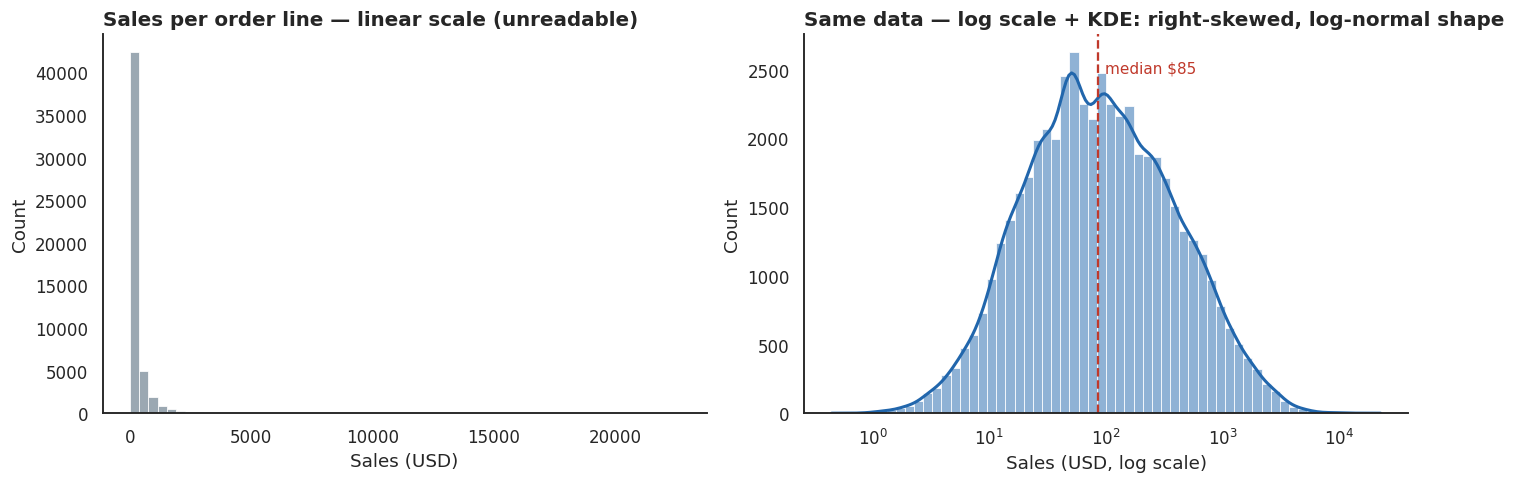

Skewness raw: 8.14  |  skewness log: 0.08


In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Linear scale — shows why log is needed
sns.histplot(df["sales"], bins=60, color="#7a8b99", ax=a1)
a1.set_title("Sales per order line — linear scale (unreadable)")
a1.set_xlabel("Sales (USD)")

# Log scale + KDE overlay
sns.histplot(df["sales"], bins=60, log_scale=True, kde=True, color=POS,
             line_kws={"lw": 2}, ax=a2)
med = df["sales"].median()
a2.axvline(med, color=HIGHLIGHT, ls="--", lw=1.5)
a2.text(med * 1.15, a2.get_ylim()[1] * .9, f"median ${med:,.0f}", color=HIGHLIGHT)
a2.set_title("Same data — log scale + KDE: right-skewed, log-normal shape")
a2.set_xlabel("Sales (USD, log scale)")
fig.tight_layout()
save(fig, "03_dist_sales_hist_kde")
plt.show()

print(f"Skewness raw: {stats.skew(df['sales']):.2f}  |  skewness log: {stats.skew(np.log10(df['sales'])):.2f}")

saved -> outputs/static/04_dist_kde_margin_by_discount.png / .svg


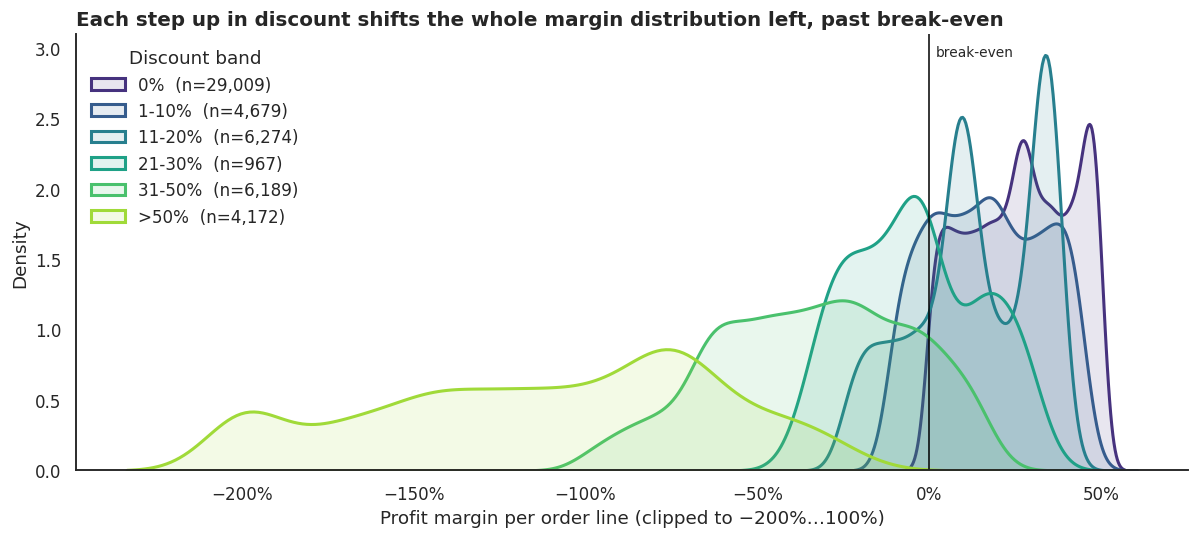

In [9]:
# KDE of profit margin per discount band — sequential (viridis) palette because
# the bands are ORDERED magnitudes.
fig, ax = plt.subplots(figsize=(11, 5))
band_colors = dict(zip(labels, sns.color_palette(SEQUENTIAL, len(labels))))
for b in labels:
    sub_m = df.loc[df["discount_band"] == b, "profit_margin"].clip(-2, 1)
    sns.kdeplot(sub_m, ax=ax, color=band_colors[b], lw=2, fill=True, alpha=.12,
                label=f"{b}  (n={len(sub_m):,})", bw_adjust=1.2)
ax.axvline(0, color="black", lw=1)
ax.text(0.02, ax.get_ylim()[1] * .95, "break-even", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Profit margin per order line (clipped to −200%…100%)")
ax.set_title("Each step up in discount shifts the whole margin distribution left, past break-even")
ax.legend(title="Discount band", frameon=False)
fig.tight_layout()
save(fig, "04_dist_kde_margin_by_discount")
plt.show()

saved -> outputs/static/05_dist_box_violin.png / .svg


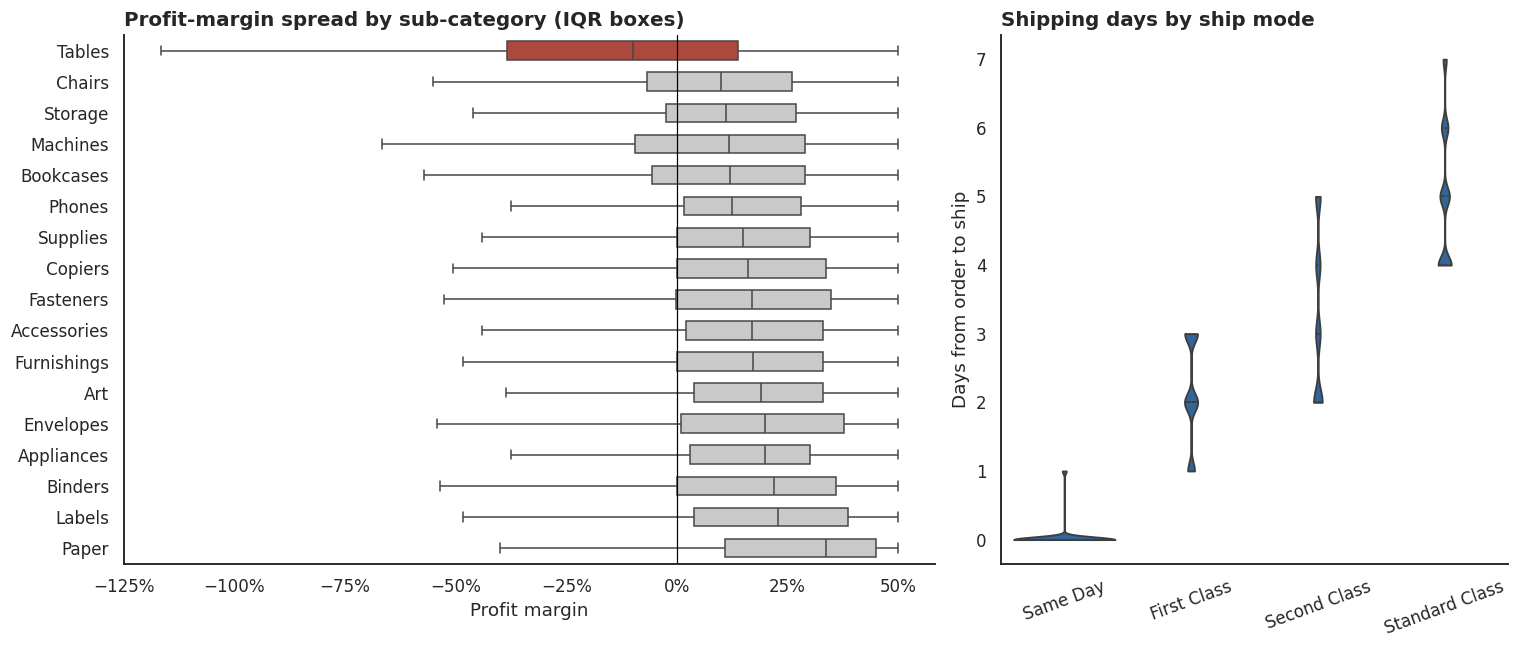

In [10]:
# Box plots (spread + outliers) of profit margin by sub-category, and a violin
# of shipping days by ship mode.
order = (df.groupby("sub_category", observed=True)["profit_margin"].median()
           .sort_values().index)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.6, 1]})

pal = {s: (HIGHLIGHT if s == "Tables" else MUTED) for s in order}
sns.boxplot(data=df, y="sub_category", x="profit_margin", order=order, palette=pal,
            hue="sub_category", legend=False, showfliers=False, width=.6, ax=a1)
a1.axvline(0, color="black", lw=.8)
a1.xaxis.set_major_formatter(mtick.PercentFormatter(1))
a1.set_title("Profit-margin spread by sub-category (IQR boxes)")
a1.set_xlabel("Profit margin"); a1.set_ylabel("")

sns.violinplot(data=df, x="ship_mode", y="ship_days", color=POS, inner="quartile",
               cut=0, ax=a2)
a2.set_title("Shipping days by ship mode")
a2.set_xlabel(""); a2.set_ylabel("Days from order to ship")
a2.tick_params(axis="x", rotation=20)
fig.tight_layout()
save(fig, "05_dist_box_violin")
plt.show()

## 4. Uncertainty & variability — confidence intervals
* **CI band:** monthly *average profit per order line* with a 95 % t-based confidence band, per market.
  Wide bands = noisy markets where a single month says little.
* **Error bars:** mean profit by discount band with bootstrap 95 % CI (Seaborn `errorbar=("ci", 95)`).
  The intervals do not overlap with zero above 20 % discount → the loss is statistically robust, not noise.

saved -> outputs/static/06_uncertainty_ci_band.png / .svg


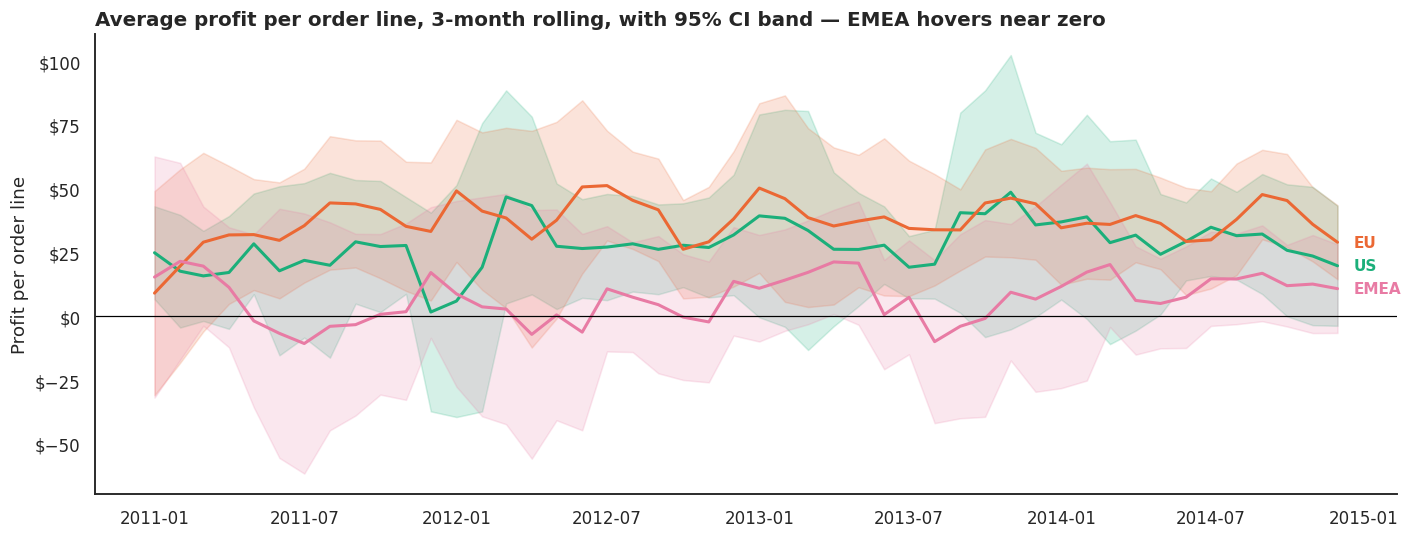

In [11]:
def mean_ci(x, conf=0.95):
    """Mean and t-based confidence interval for a 1-D sample."""
    x = np.asarray(x); n = len(x); m = x.mean()
    h = stats.sem(x) * stats.t.ppf((1 + conf) / 2, n - 1) if n > 1 else 0
    return pd.Series({"mean": m, "lo": m - h, "hi": m + h, "n": n})

fig, ax = plt.subplots(figsize=(13, 5))
for mk in ["US", "EU", "EMEA"]:      # 3 markets max to keep it readable
    g = (df[df["market"] == mk].groupby("year_month")["profit"].apply(mean_ci).unstack())
    roll = g.rolling(3, center=True, min_periods=1).mean()   # 3-month smoothing
    ax.plot(roll.index, roll["mean"], color=MARKET_COLORS[mk], lw=2)
    ax.fill_between(roll.index, roll["lo"], roll["hi"], color=MARKET_COLORS[mk], alpha=.18)
    ax.text(roll.index[-1] + pd.Timedelta(days=20), roll["mean"].iloc[-1], mk,
            color=MARKET_COLORS[mk], fontweight="bold", va="center")   # direct label, no legend box
ax.axhline(0, color="black", lw=.8)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title("Average profit per order line, 3-month rolling, with 95% CI band — EMEA hovers near zero")
ax.set_ylabel("Profit per order line")
fig.tight_layout()
save(fig, "06_uncertainty_ci_band")
plt.show()

saved -> outputs/static/07_uncertainty_error_bars.png / .svg


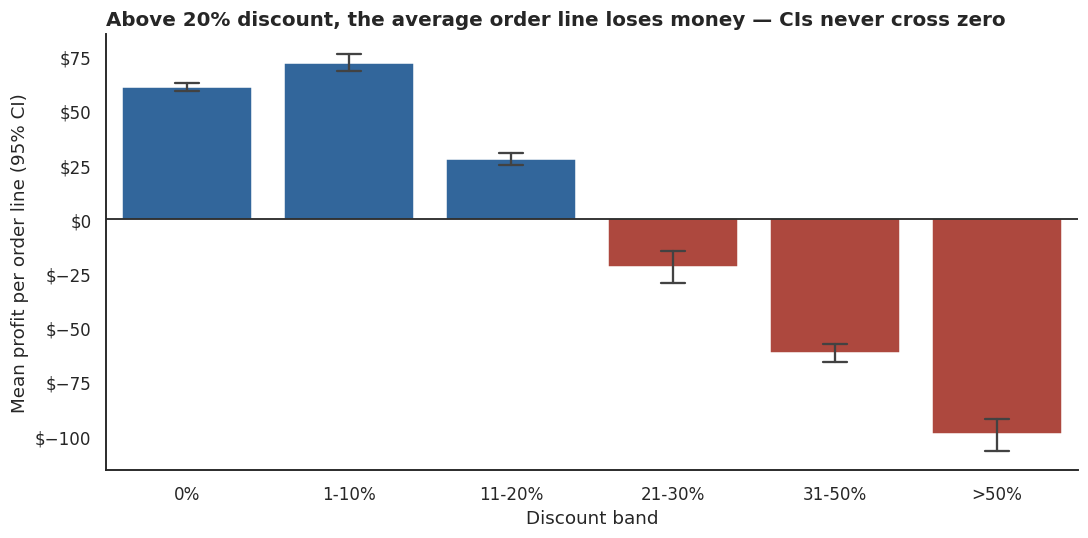

,order_lines,sales,profit,loss_rate,margin
discount_band,,,,,
0%,29009,"$6,992,411","$1,770,695",0%,25.3%
1-10%,4679,"$1,962,619","$338,189",19%,17.2%
11-20%,6274,"$1,757,261","$173,255",23%,9.9%
21-30%,967,"$382,555","$-21,156",62%,-5.5%
31-50%,6189,"$1,176,031","$-380,945",87%,-32.4%
>50%,4172,"$371,625","$-412,582",100%,-111.0%


In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x="discount_band", y="profit", errorbar=("ci", 95), n_boot=1000,
            palette=[POS, POS, POS, NEG, NEG, NEG], hue="discount_band", legend=False,
            capsize=.15, err_kws={"linewidth": 1.5}, ax=ax, seed=42)
ax.axhline(0, color="black", lw=1)                         # 0-baseline
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Discount band"); ax.set_ylabel("Mean profit per order line (95% CI)")
ax.set_title("Above 20% discount, the average order line loses money — CIs never cross zero")
fig.tight_layout()
save(fig, "07_uncertainty_error_bars")
plt.show()

summary = (df.groupby("discount_band", observed=True)
             .agg(order_lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"),
                  loss_rate=("is_loss", "mean")))
summary["margin"] = summary["profit"] / summary["sales"]
summary.style.format({"sales": "${:,.0f}", "profit": "${:,.0f}", "loss_rate": "{:.0%}", "margin": "{:.1%}"})

## 5. X-Y relationships
### 5.1 Correlation matrix heatmap (Seaborn)
Diverging palette centred on 0 (blue = positive, red = negative), upper triangle masked to remove redundancy.
We show **Pearson** (linear) and **Spearman** (rank, robust to the heavy right skew).

saved -> outputs/static/08_correlation_heatmap.png / .svg


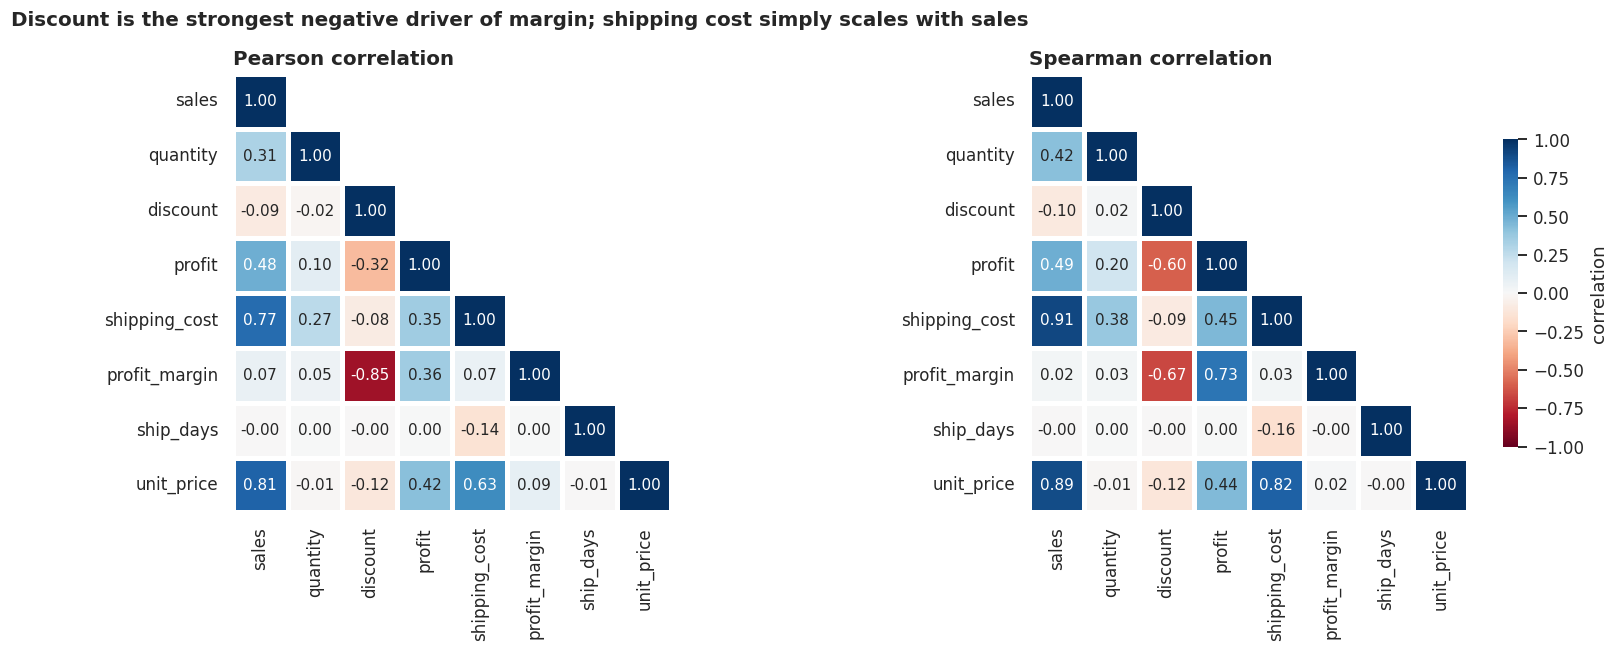

Spearman discount ↔ profit_margin: -0.669


In [13]:
num = df[["sales", "quantity", "discount", "profit", "shipping_cost", "profit_margin", "ship_days", "unit_price"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = num.corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True,
                fmt=".2f", linewidths=2, linecolor="white", square=True, cbar=ax is axes[1],
                cbar_kws={"shrink": .7, "label": "correlation"}, ax=ax)
    ax.set_title(f"{method.title()} correlation")
fig.suptitle("Discount is the strongest negative driver of margin; shipping cost simply scales with sales",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "08_correlation_heatmap")
plt.show()
print("Spearman discount ↔ profit_margin:", round(num.corr("spearman").loc["discount", "profit_margin"], 3))

### 5.2 Interactive bubble chart (Plotly)
One bubble = one *market × sub-category* combination. **x** = average discount, **y** = profit margin,
**size** = sales, **colour** = market (qualitative). Hover for details; click legend items to filter.

In [14]:
bub = (df.groupby(["market", "sub_category"], observed=True)
         .agg(sales=("sales", "sum"), profit=("profit", "sum"), avg_discount=("discount", "mean"),
              orders=("order_id", "nunique"))
         .reset_index())
bub["margin"] = bub["profit"] / bub["sales"]

fig = px.scatter(bub, x="avg_discount", y="margin", size="sales", color="market",
                 color_discrete_map=MARKET_COLORS, category_orders={"market": MARKET_ORDER},
                 hover_name="sub_category", size_max=45, trendline="ols", trendline_scope="overall",
                 trendline_color_override="black",
                 hover_data={"sales": ":$,.0f", "profit": ":$,.0f", "orders": True,
                             "avg_discount": ":.1%", "margin": ":.1%"},
                 labels={"avg_discount": "Average discount", "margin": "Profit margin", "market": "Market"},
                 title="Higher average discount → lower margin, in every market (bubble = sales)")
fig.add_hline(y=0, line_color="black", line_width=1)
fig.update_layout(template="simple_white", xaxis_tickformat=".0%", yaxis_tickformat=".0%",
                  legend_title_text="Market")
fig.update_traces(marker=dict(line=dict(width=1, color="white"), opacity=.85), selector=dict(mode="markers"))
save_plotly(fig, "09_bubble_discount_margin")
fig.show()

saved -> outputs/html/09_bubble_discount_margin.html (+ static png/svg)


## 6. Geospatial — profit by country (geographic coordinate system)
Choropleth with a **diverging** scale centred at \$0 so loss-making countries appear red.

In [15]:
geo = (df.groupby(["country", "iso3", "market"], observed=True)
         .agg(sales=("sales", "sum"), profit=("profit", "sum"), avg_discount=("discount", "mean"))
         .reset_index())
geo["margin"] = geo["profit"] / geo["sales"]
lim = geo["profit"].abs().quantile(.95)     # symmetric limits so 0 is the neutral midpoint

fig = px.choropleth(geo, locations="iso3", color="profit", hover_name="country",
                    color_continuous_scale=DIVERGING, range_color=(-lim, lim),
                    color_continuous_midpoint=0, projection="natural earth",
                    hover_data={"iso3": False, "market": True, "sales": ":$,.0f",
                                "profit": ":$,.0f", "avg_discount": ":.1%", "margin": ":.1%"},
                    title="Total profit by country, 2011-2014 (red = loss)")
fig.update_layout(template="simple_white", coloraxis_colorbar=dict(title="Profit", tickformat="$,.0f"),
                  margin=dict(l=0, r=0, t=50, b=0))
save_plotly(fig, "10_choropleth_profit")
fig.show()

print("Bottom 6 countries by profit:")
geo.sort_values("profit").head(6)[["country", "market", "sales", "profit", "avg_discount", "margin"]]

saved -> outputs/html/10_choropleth_profit.html (+ static png/svg)


Bottom 6 countries by profit:


,country,market,sales,profit,avg_discount,margin
135,Turkey,EMEA,108507.94800,-98447.23200,0.600000,-0.907281
96,Nigeria,Africa,54350.35200,-80750.71800,0.700000,-1.485744
92,Netherlands,EU,77514.94500,-41070.07500,0.481839,-0.529834
55,Honduras,LATAM,90125.64860,-29482.37140,0.406833,-0.327125
98,Pakistan,APAC,58872.61200,-22446.64800,0.444578,-0.381275
4,Argentina,LATAM,57511.78328,-18693.79672,0.433210,-0.325043


saved -> outputs/static/11_loss_countries.png / .svg


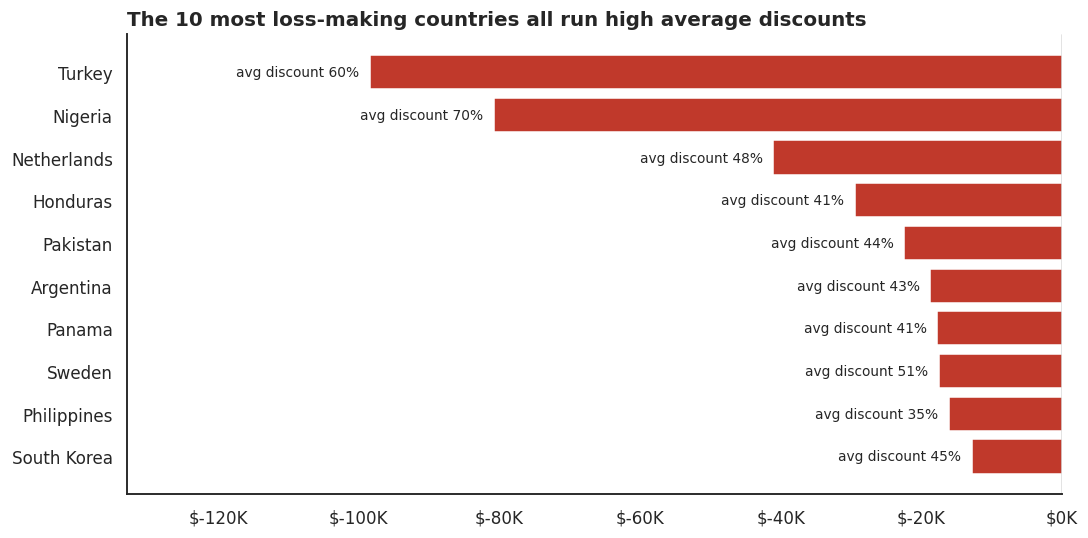

Company-wide average discount: 14.3%


In [16]:
# Static companion: the loss-making countries vs their average discount.
worst = geo.sort_values("profit").head(10).sort_values("profit", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(worst["country"], worst["profit"], color=NEG)
ax.axvline(0, color="black", lw=.8)
for y, (p, d) in enumerate(zip(worst["profit"], worst["avg_discount"])):
    ax.text(p - 1500, y, f"avg discount {d:.0%}", ha="right", va="center", fontsize=9)
ax.set_xlim(left=worst["profit"].min() * 1.35)   # room for the direct labels
ax.xaxis.set_major_formatter(usd)
ax.set_title("The 10 most loss-making countries all run high average discounts")
ax.tick_params(left=False)
fig.tight_layout()
save(fig, "11_loss_countries")
plt.show()
print(f"Company-wide average discount: {df['discount'].mean():.1%}")

## 7. Proportions — part-to-whole

In [17]:
tm = (df.groupby(["market", "category", "sub_category"], observed=True)
        .agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index())
tm["margin"] = tm["profit"] / tm["sales"]
fig = px.treemap(tm, path=[px.Constant("All markets"), "market", "category", "sub_category"],
                 values="sales", color="margin", color_continuous_scale=DIVERGING,
                 color_continuous_midpoint=0, range_color=(-0.3, 0.3),
                 hover_data={"profit": ":$,.0f", "margin": ":.1%"},
                 title="Sales composition (area) coloured by profit margin — click to drill down")
fig.update_layout(coloraxis_colorbar=dict(title="Margin", tickformat=".0%"), margin=dict(t=50, l=10, r=10, b=10))
save_plotly(fig, "12_treemap_market_category")
fig.show()

saved -> outputs/html/12_treemap_market_category.html (+ static png/svg)


saved -> outputs/static/13_stacked_area_category.png / .svg


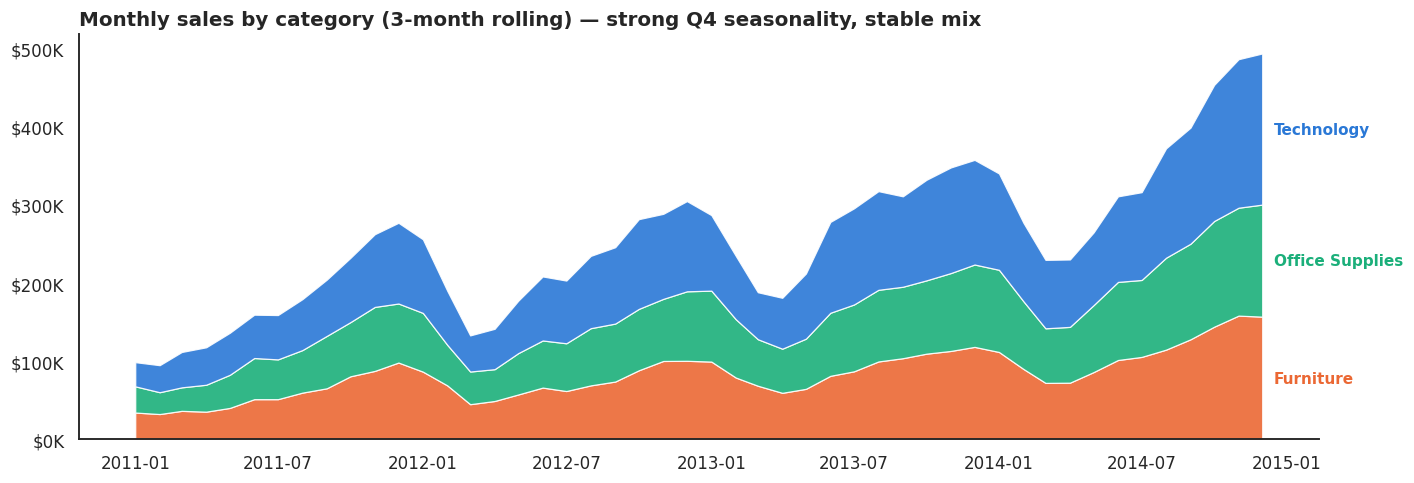

In [18]:
# Stacked area: monthly sales composition by category (part-to-whole over time)
area = (df.pivot_table(index="year_month", columns="category", values="sales",
                       aggfunc="sum", observed=True).rolling(3, min_periods=1).mean())
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.stackplot(area.index, area.T.values, colors=[CATEGORY_COLORS[c] for c in area.columns],
             alpha=.9, edgecolor="white", linewidth=.8)
y_cum = area.cumsum(axis=1).iloc[-1]
for c in area.columns:   # direct labels at the right edge instead of a legend
    ax.text(area.index[-1] + pd.Timedelta(days=15), y_cum[c] - area[c].iloc[-1] / 2, c,
            color=CATEGORY_COLORS[c], fontweight="bold", va="center")
ax.set_ylim(bottom=0); ax.yaxis.set_major_formatter(usd)
ax.set_title("Monthly sales by category (3-month rolling) — strong Q4 seasonality, stable mix")
fig.tight_layout()
save(fig, "13_stacked_area_category")
plt.show()

## 8. Cyclical data — polar coordinate system
Months are cyclical (December is next to January), so a **polar bar chart** is the natural coordinate system.

In [19]:
cyc = df.groupby(["order_month", "order_month_name"])["sales"].sum().reset_index()
fig = px.bar_polar(cyc, r="sales", theta="order_month_name", color="sales",
                   color_continuous_scale="Viridis",   # sequential: ordered magnitude
                   title="Sales seasonality by month (2011-2014 total) — Q4 peaks, Q1 trough")
fig.update_layout(template="simple_white", polar=dict(radialaxis=dict(showticklabels=False, ticks="")),
                  coloraxis_colorbar=dict(title="Sales", tickformat="$,.0s"))
save_plotly(fig, "14_polar_seasonality", width=800, height=700)
fig.show()

saved -> outputs/html/14_polar_seasonality.html (+ static png/svg)


## 9. Key numbers for the executive story (Setup → Conflict → Resolution)

In [20]:
loss = df[df["is_loss"]]
hi_disc = df["discount"] > 0.20
k = {
    "Total sales 2011-14": f"${df['sales'].sum()/1e6:.2f}M",
    "Total profit 2011-14": f"${df['profit'].sum()/1e6:.2f}M",
    "Sales growth 2011→2014": f"{yr['sales'].iloc[-1]/yr['sales'].iloc[0]-1:.0%}",
    "Margin 2011 / 2014": f"{yr['margin'].iloc[0]:.1%} / {yr['margin'].iloc[-1]:.1%}",
    "Order lines with a loss": f"{len(loss):,} ({len(loss)/len(df):.0%})",
    "Total value lost on loss lines": f"${-loss['profit'].sum()/1e3:,.0f}K",
    "Loss lines that had a discount": f"{(loss['discount'] > 0).mean():.0%}",
    "Share of lines with discount >20%": f"{hi_disc.mean():.0%}",
    "Profit of lines with discount >20%": f"${df.loc[hi_disc, 'profit'].sum()/1e3:,.0f}K",
    "Margin at 0% discount": f"{summary.loc['0%', 'margin']:.1%}",
    "Tables profit": f"${sub.loc['Tables', 'profit']/1e3:,.0f}K",
}
# What-if: cap discounts at 20% -> assume loss lines above 20% would at least break even
uplift = -df.loc[hi_disc, "profit"].sum()
k["What-if: >20% lines break even → profit uplift"] = (
    f"+${uplift/1e3:,.0f}K (+{uplift/df['profit'].sum():.0%})")
pd.Series(k, name="value").to_frame()

,value
Total sales 2011-14,$12.64M
Total profit 2011-14,$1.47M
Sales growth 2011→2014,90%
Margin 2011 / 2014,11.0% / 11.7%
Order lines with a loss,"12,544 (24%)"
Total value lost on loss lines,$921K
Loss lines that had a discount,100%
Share of lines with discount >20%,22%
Profit of lines with discount >20%,$-815K
Margin at 0% discount,25.3%


### Story arc
* **Setup:** Global Superstore nearly doubled sales (+90 %) between 2011 and 2014 across 147 countries.
* **Conflict / Insight:** profit margin never moved (~11-12 %). A quarter of all order lines lose money,
  and **100 % of those losses carry a discount**. Above a 20 % discount the average line is unprofitable
  (CI never crosses 0). Losses concentrate in *Tables* and in high-discount countries
  (Turkey, Nigeria, Netherlands, Honduras…).
* **Resolution:** (1) cap discretionary discounts at 20 % with an approval workflow above it,
  (2) re-price / bundle *Tables*, (3) country-level discount audit for the 10 loss-making countries,
  (4) track *margin*, not just sales, as the regional KPI in the executive dashboard.